# Bank Marketing: Final Model Evaluation

## Objective

This notebook evaluates the selected tuned histogram gradient boosting model on the untouched test set.

The test set was not used during model selection or hyperparameter tuning.

The final evaluation includes:

- classification metrics
- confusion matrix
- ROC curve
- precision-recall curve
- threshold analysis
- interpretation of strengths and weaknesses

In [1]:
from ucimlrepo import fetch_ucirepo

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

In [2]:
bank_marketing = fetch_ucirepo(id=222)

X = bank_marketing.data.features.copy()
y = bank_marketing.data.targets["y"].map({
    "no": 0,
    "yes": 1
})

# Exclude duration for the realistic pre-contact scenario
X = X.drop(columns=["duration"])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

numerical_features = (
    X_train
    .select_dtypes(include="number")
    .columns
    .tolist()
)

categorical_features = (
    X_train
    .select_dtypes(exclude="number")
    .columns
    .tolist()
)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

Training shape: (36168, 15)
Test shape: (9043, 15)


In [3]:
numerical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="missing"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_pipeline,
            numerical_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)

final_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            HistGradientBoostingClassifier(
                min_samples_leaf=40,
                max_leaf_nodes=31,
                max_iter=100,
                learning_rate=0.1,
                l2_regularization=1.0,
                random_state=42
            )
        )
    ]
)

print(final_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'balance',
                                                   'day_of_week', 'campaign',
                                                   'pdays', 'previous']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='missing',
                                                                                 strategy='c

In [4]:
final_model.fit(X_train, y_train)

test_predictions = final_model.predict(X_test)
test_probabilities = final_model.predict_proba(X_test)[:, 1]

print("Final model trained successfully.")

Final model trained successfully.


## Final test-set performance

The selected tuned histogram gradient boosting model is evaluated once on the untouched test set.

These results represent the final unbiased estimate of model performance.

In [5]:
final_results = pd.Series({
    "accuracy": accuracy_score(
        y_test,
        test_predictions
    ),
    "precision": precision_score(
        y_test,
        test_predictions,
        zero_division=0
    ),
    "recall": recall_score(
        y_test,
        test_predictions,
        zero_division=0
    ),
    "f1_score": f1_score(
        y_test,
        test_predictions,
        zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_test,
        test_probabilities
    ),
    "pr_auc": average_precision_score(
        y_test,
        test_probabilities
    )
})

display(
    final_results
    .to_frame("Final histogram boosting model")
    .round(4)
)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        test_predictions,
        zero_division=0
    )
)

,Final histogram boosting model
accuracy,0.8966
precision,0.6534
recall,0.2476
f1_score,0.3592
roc_auc,0.8042
pr_auc,0.4652



Classification report:
              precision    recall  f1-score   support

           0       0.91      0.98      0.94      7985
           1       0.65      0.25      0.36      1058

    accuracy                           0.90      9043
   macro avg       0.78      0.62      0.65      9043
weighted avg       0.88      0.90      0.88      9043



## Confusion matrix

The confusion matrix shows how many customers were classified correctly and incorrectly at the default probability threshold of 0.5.

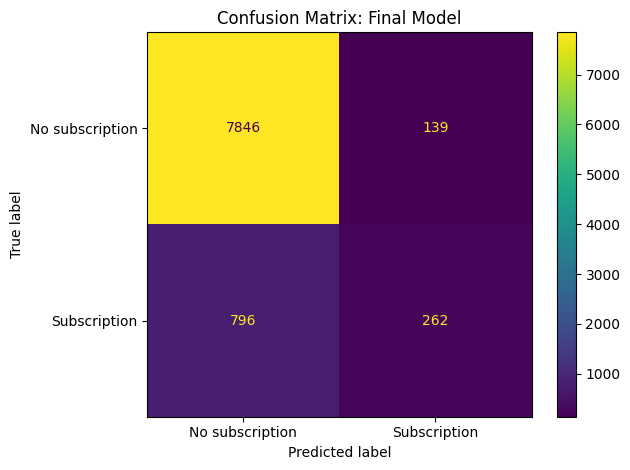

In [6]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["No subscription", "Subscription"]
)

plt.title("Confusion Matrix: Final Model")
plt.tight_layout()
plt.show()

### Final evaluation interpretation

The final histogram gradient boosting model achieves:

- accuracy of 89.6%
- precision of 65.3%
- recall of 24.8%
- F1-score of 35.9%
- ROC-AUC of 0.804
- PR-AUC of 0.465

The model correctly identifies 262 of the 1,058 actual subscribers.

It also produces 139 false positives, meaning 139 non-subscribers were incorrectly predicted as subscribers. However, it misses 796 subscribers, which explains the relatively low recall.

The high precision means that when the model predicts subscription, it is often correct. The lower recall means that the default threshold of 0.5 makes the model conservative.

The ROC-AUC and PR-AUC indicate that the model ranks likely subscribers reasonably well, even though the default classification threshold does not identify most of them.

## ROC and precision-recall curves

The ROC curve evaluates the model across all classification thresholds by comparing the true-positive rate and false-positive rate.

The precision-recall curve focuses specifically on performance for the positive class and is especially useful for imbalanced datasets.

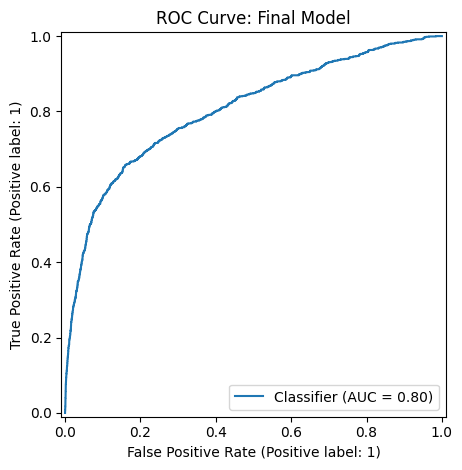

In [7]:
RocCurveDisplay.from_predictions(
    y_test,
    test_probabilities
)

plt.title("ROC Curve: Final Model")
plt.tight_layout()
plt.show()

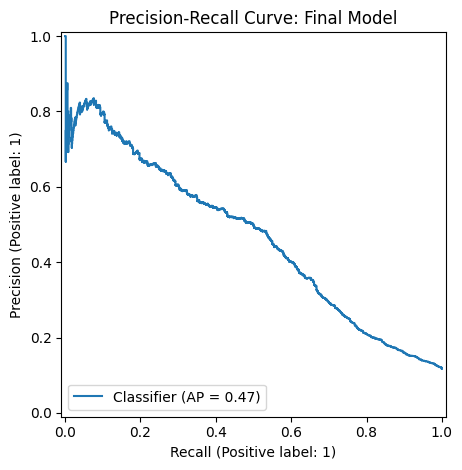

In [8]:
PrecisionRecallDisplay.from_predictions(
    y_test,
    test_probabilities
)

plt.title("Precision-Recall Curve: Final Model")
plt.tight_layout()
plt.show()

### Curve interpretation

The ROC curve has an area under the curve of approximately 0.80. This means that the model generally ranks actual subscribers above non-subscribers reasonably well.

The precision-recall curve has an average precision of approximately 0.47, which is substantially higher than the positive-class prevalence of approximately 0.12.

Because the dataset is imbalanced, the precision-recall curve is especially informative. It shows that increasing recall generally reduces precision, so the final classification threshold should depend on the business objective.

## Classification threshold analysis

The default classification threshold is 0.5.

Lowering the threshold causes the model to predict more customers as subscribers. This usually increases recall but reduces precision.

Several thresholds are compared to show this trade-off.

In [9]:
threshold_results = []

for threshold in [0.20, 0.30, 0.40, 0.50, 0.60]:
    threshold_predictions = (
        test_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_test,
            threshold_predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_test,
            threshold_predictions,
            zero_division=0
        ),
        "f1_score": f1_score(
            y_test,
            threshold_predictions,
            zero_division=0
        ),
        "predicted_subscribers": threshold_predictions.sum()
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df
    .set_index("threshold")
    .round(4)
)

,precision,recall,f1_score,predicted_subscribers
threshold,,,,
0.2,0.4637,0.5425,0.5000,1238
0.3,0.5190,0.4527,0.4836,923
0.4,0.5719,0.3497,0.4340,647
0.5,0.6534,0.2476,0.3592,401
0.6,0.7137,0.1720,0.2772,255


### Threshold interpretation

The classification threshold strongly affects model behaviour.

At the default threshold of 0.5, the model has relatively high precision but low recall. It predicts only 401 customers as subscribers and misses many actual subscribers.

Lowering the threshold increases the number of positive predictions. At a threshold of 0.2, recall rises to approximately 54.3% and the F1-score improves to 0.50, although precision falls to approximately 46.4%.

Among the tested thresholds, 0.2 provides the strongest F1-score and the most balanced trade-off between precision and recall.

However, the final threshold should depend on business priorities:

- use a higher threshold when unnecessary customer contacts are expensive
- use a lower threshold when missing a potential subscriber is more costly

## Final conclusion

The tuned histogram gradient boosting model achieved strong ranking performance on the untouched test set, with a ROC-AUC of approximately 0.80 and a PR-AUC of approximately 0.47.

At the default threshold of 0.5, the model produced high precision but low recall. Threshold analysis showed that lowering the threshold to 0.2 improved recall and F1-score substantially.

The model is therefore useful for ranking customers by likelihood of subscription, but the final classification threshold should be selected according to campaign costs and business priorities.

### Strengths

- Stronger performance than the dummy baseline
- Good ROC-AUC and PR-AUC
- Handles non-linear relationships
- Works well with mixed numerical and categorical data
- Uses a reproducible preprocessing and modeling pipeline
- Avoids using `duration` in the realistic pre-contact scenario

### Limitations

- The target class is imbalanced
- Recall remains limited at the default threshold
- Some features contain substantial missingness
- The model may reflect historical campaign bias
- Results are based on one banking dataset and may not generalize to other institutions
- Predictions indicate likelihood, not certainty